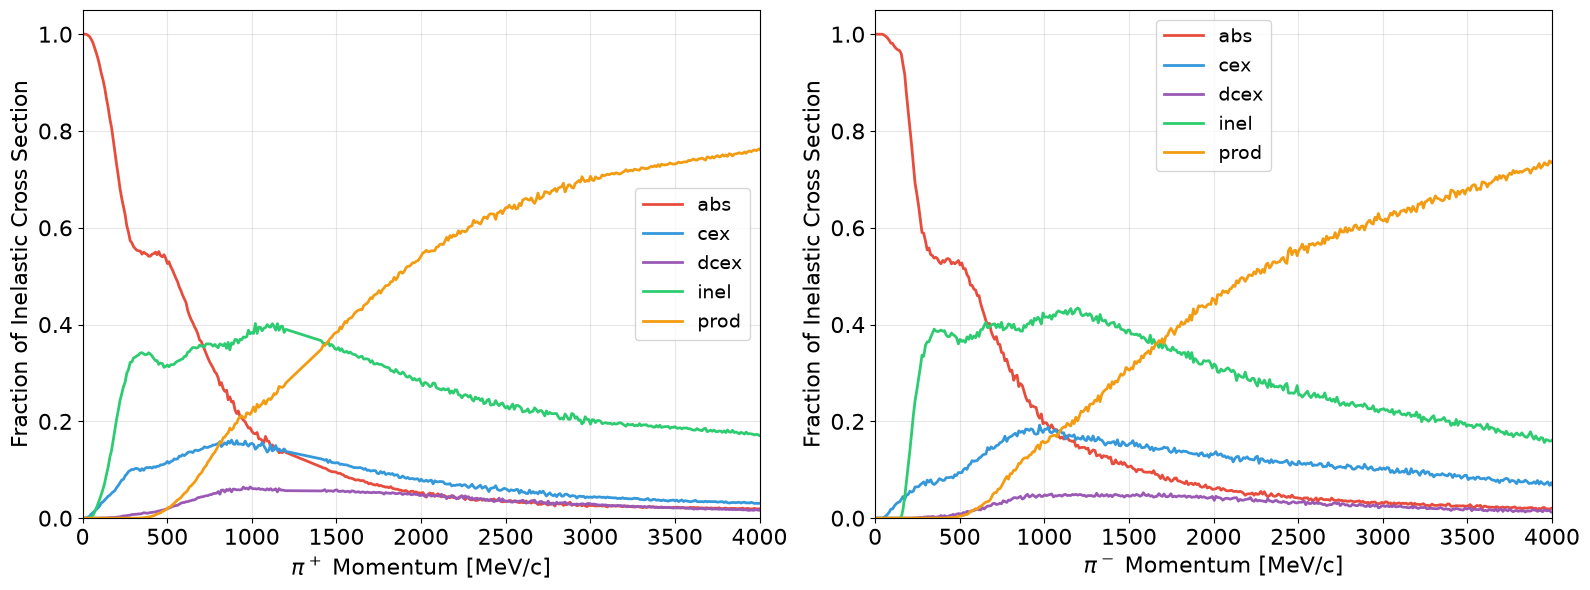

Saved: fracs_piplus_piminus.png


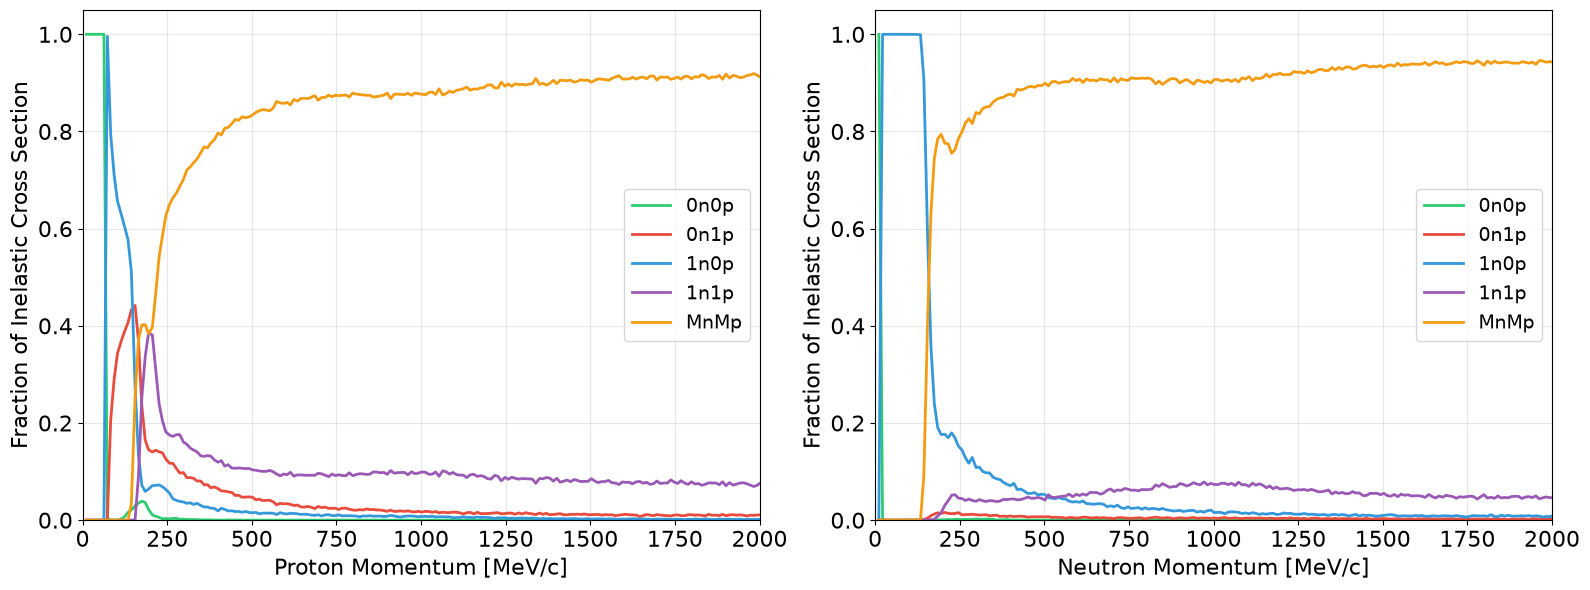

Saved: fracs_proton_neutron.png


In [2]:
# %%  ========= STANDALONE CELL: Two Fracs Plots (PiPlus/PiMinus, Proton/Neutron) =========
import uproot
import numpy as np
import matplotlib.pyplot as plt
import os

def read_tgraph(file, name):
    graph = file[name]
    x = np.array(graph.member("fX"))
    y = np.array(graph.member("fY"))
    return x, y

# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
pardata_dir = os.environ.get(
    "DUNE_PARDATA_DIR",
    "/cvmfs/dune.opensciencegrid.org/products/dune/dune_pardata/v01_84_00"
)

piplus_path  = os.path.join(pardata_dir, "Geant4ReweightInput/LAr_PiPlus_cascade_0_9000.root")
piminus_path = "/global/cfs/cdirs/dune/users/mazam/G4RW/G4Cascade/LAr_PiMinus_cascade_0_9000.root"
proton_path  = "/global/cfs/cdirs/dune/users/mazam/G4RW/G4Cascade/LAr_P_cascade_0_9000.root"
neutron_path = "/global/cfs/cdirs/dune/users/mazam/G4RW/G4Cascade/LAr_N_cascade_0_9000.root"

# ---------------------------------------------------------------------------
# Load pion (5-channel: abs, cex, dcex, inel, prod)
# ---------------------------------------------------------------------------
pion_channels = ["abs", "cex", "dcex", "inel", "prod"]
pion_colors = {"abs": "#e74c3c", "cex": "#3498db", "dcex": "#9b59b6",
               "inel": "#2ecc71", "prod": "#f39c12"}

piplus_file  = uproot.open(piplus_path)
piminus_file = uproot.open(piminus_path)

piplus_data  = {ch: read_tgraph(piplus_file, ch)  for ch in pion_channels}
piminus_data = {ch: read_tgraph(piminus_file, ch) for ch in pion_channels}

x_pip = piplus_data["abs"][0]
x_pim = piminus_data["abs"][0]

# ---------------------------------------------------------------------------
# Load nucleon (5-channel: 0n0p, 0n1p, 1n0p, 1n1p, Other)
# ---------------------------------------------------------------------------
nucleon_channels = ["0n0p", "0n1p", "1n0p", "1n1p", "Other"]
nucleon_colors = {"0n0p": "#2ecc71", "0n1p": "#e74c3c", "1n0p": "#3498db",
                   "1n1p": "#9b59b6", "Other": "#f39c12"}
nucleon_labels = {"0n0p": "0n0p", "0n1p": "0n1p", "1n0p": "1n0p",
                   "1n1p": "1n1p", "Other": "MnMp"}

proton_file  = uproot.open(proton_path)
neutron_file = uproot.open(neutron_path)

proton_data  = {ch: read_tgraph(proton_file, ch)  for ch in nucleon_channels}
neutron_data = {ch: read_tgraph(neutron_file, ch) for ch in nucleon_channels}

x_p = proton_data["0n0p"][0]
x_n = neutron_data["0n0p"][0]

# ---------------------------------------------------------------------------
# Font scaling (matching established slide/notebook convention)
# ---------------------------------------------------------------------------
LABEL_SIZE  = 16
TICK_SIZE   = 16
LEGEND_SIZE = 14

# ---------------------------------------------------------------------------
# Figure 1: PiPlus | PiMinus
# ---------------------------------------------------------------------------
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 6))

ax = axes1[0]
for ch in pion_channels:
    x, y = piplus_data[ch]
    ax.plot(x, y, '-', linewidth=2, color=pion_colors[ch], label=ch)
ax.set_xlabel(r'$\pi^+$ Momentum [MeV/c]', fontsize=LABEL_SIZE)
ax.set_ylabel('Fraction of Inelastic Cross Section', fontsize=LABEL_SIZE)
ax.set_xlim(x_pip[0], x_pip[-1])
ax.set_xlim(0, 4000)
ax.set_ylim(0, 1.05)
ax.tick_params(axis='both', labelsize=TICK_SIZE)
ax.legend(fontsize=LEGEND_SIZE)
ax.grid(True, alpha=0.3)

ax = axes1[1]
for ch in pion_channels:
    x, y = piminus_data[ch]
    ax.plot(x, y, '-', linewidth=2, color=pion_colors[ch], label=ch)
ax.set_xlabel(r'$\pi^-$ Momentum [MeV/c]', fontsize=LABEL_SIZE)
ax.set_ylabel('Fraction of Inelastic Cross Section', fontsize=LABEL_SIZE)
ax.set_xlim(x_pim[0], x_pim[-1])
ax.set_xlim(0, 4000)
ax.set_ylim(0, 1.05)
ax.tick_params(axis='both', labelsize=TICK_SIZE)
ax.legend(fontsize=LEGEND_SIZE)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fracs_piplus_piminus.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fracs_piplus_piminus.png")

# ---------------------------------------------------------------------------
# Figure 2: Proton | Neutron
# ---------------------------------------------------------------------------
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))

ax = axes2[0]
for ch in nucleon_channels:
    x, y = proton_data[ch]
    ax.plot(x, y, '-', linewidth=2, color=nucleon_colors[ch], label=nucleon_labels[ch])
ax.set_xlabel('Proton Momentum [MeV/c]', fontsize=LABEL_SIZE)
ax.set_ylabel('Fraction of Inelastic Cross Section', fontsize=LABEL_SIZE)
ax.set_xlim(x_p[0], x_p[-1])
ax.set_xlim(0, 2000)
ax.set_ylim(0, 1.05)
ax.tick_params(axis='both', labelsize=TICK_SIZE)
ax.legend(fontsize=LEGEND_SIZE)
ax.grid(True, alpha=0.3)

ax = axes2[1]
for ch in nucleon_channels:
    x, y = neutron_data[ch]
    ax.plot(x, y, '-', linewidth=2, color=nucleon_colors[ch], label=nucleon_labels[ch])
ax.set_xlabel('Neutron Momentum [MeV/c]', fontsize=LABEL_SIZE)
ax.set_ylabel('Fraction of Inelastic Cross Section', fontsize=LABEL_SIZE)
ax.set_xlim(x_n[0], x_n[-1])
ax.set_xlim(0, 2000)
ax.set_ylim(0, 1.05)
ax.tick_params(axis='both', labelsize=TICK_SIZE)
ax.legend(fontsize=LEGEND_SIZE)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fracs_proton_neutron.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fracs_proton_neutron.png")